### Imports

In [1]:
# ============================================================
# NOTEBOOK 02: ARCFACE EMBEDDING VALIDATION
# ────────────────────────────────────────────────────────────
# Exp A → Sanity check (same person / kin / non-kin)
# Exp B → AUC + ROC (kin vs non-kin discrimination)
# Exp C → Similarity by relationship (father/mother × son/daughter)
# Exp D → Effect of averaging K photos on stability
# ============================================================

import os
import time
import random
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

from deepface import DeepFace
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.stats import mannwhitneyu
import pickle, numpy as np, cv2, time
from tqdm import tqdm
from pathlib import Path
from pathlib import PurePosixPath


# Plotting and warnings configuration
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120

print("Libraries loaded")


Libraries loaded


### Configuration and constants

In [2]:
# ============================================================
# CONFIGURATION
# ============================================================

BASE_DIR   = Path('..').resolve()
RUTA_FIDS  = BASE_DIR / 'data' / 'raw' / 'FIDs'
RUTA_CSV   = BASE_DIR / 'data' / 'processed' / 'tripletes_fiw.csv'
CACHE_DIR  = BASE_DIR / 'results'
CACHE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_FILE = CACHE_DIR / 'cache_embeddings_exp.pkl'
SAVE_EVERY = 500


SEED     = 42
IMG_EXTS = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')

random.seed(SEED)
np.random.seed(SEED)

# Check
for nombre, ruta in [("FIDs", RUTA_FIDS), ("CSV", RUTA_CSV)]:
    icon = "ok" if ruta.exists() else "error"
    print(f"  {icon} {nombre}: {ruta}")

  ok FIDs: <project-root>\data\raw\FIDs
  ok CSV: <project-root>\data\processed\tripletes_fiw.csv


### Data loading

In [3]:
# ============================================================
# DATA LOADING
# ============================================================
def norm_posix(ruta):
    """Normalize a path to posix format: F0001/MID1/P00001_face2.jpg"""
    return str(PurePosixPath(ruta))

def familia_desde_ruta(ruta):
    """Extract the family from a path: F0001/MID1/P00001_face2.jpg → F0001"""
    return ruta.split('/')[0]

df = pd.read_csv(RUTA_CSV, dtype=str)
for c in ['p1_papa', 'p1_mama', 'p2']:
    df[c] = df[c].map(norm_posix)
df['familia'] = df['p2'].map(familia_desde_ruta)

familias_disco = set(
    d for d in os.listdir(RUTA_FIDS) if os.path.isdir(RUTA_FIDS / d)
)
familias = sorted(set(df['familia'].unique()) & familias_disco)

print(f"  Triads in CSV:             {len(df):,}")
print(f"  Families on disk:          {len(familias_disco)}")
print(f"  Families with triads:      {len(familias)}")
print(f"  Columnas:                  {df.columns.tolist()}")

  Triads in CSV:             2,299,212
  Families on disk:          980
  Families with triads:      788
  Columnas:                  ['p1_papa', 'p1_mama', 'p2', 'familia']


In [ ]:
# ============================================================
# CELL 2: GPU extraction
# ============================================================
import pickle, numpy as np, cv2, time
from tqdm import tqdm
from pathlib import Path
from insightface.app import FaceAnalysis

RUTA_FIDS = Path(extract_to)
# If the zip contains an FIDs folder inside, adjust:
RUTA_FIDS = Path(extract_to) / "FIDs"

IMG_EXTS = {'.jpg', '.jpeg', '.png'}
SAVE_EVERY = 1000
EMB_FILE = f"{DRIVE_PATH}/data/embeddings/arcface_insightface.pkl"

# ── GPU! ──
app = FaceAnalysis(name="buffalo_l", providers=['CUDAExecutionProvider'])
app.prepare(ctx_id=0, det_size=(320, 320))
print(" InsightFace on GPU")

def extraer_embedding_con_padding(full_path, app):
    try:
        img_bgr = cv2.imread(str(full_path))
        if img_bgr is None:
            return None
        h, w = img_bgr.shape[:2]
        pad_h, pad_w = int(h * 0.5), int(w * 0.5)
        img_padded = cv2.copyMakeBorder(
            img_bgr, pad_h, pad_h, pad_w, pad_w,
            cv2.BORDER_CONSTANT, value=(0, 0, 0)
        )
        faces = app.get(img_padded)
        if len(faces) == 0:
            pad_h2, pad_w2 = int(h * 1.0), int(w * 1.0)
            img_padded2 = cv2.copyMakeBorder(
                img_bgr, pad_h2, pad_h2, pad_w2, pad_w2,
                cv2.BORDER_CONSTANT, value=(128, 128, 128)
            )
            faces = app.get(img_padded2)
            if len(faces) == 0:
                return None
        face = max(faces, key=lambda f: (f.bbox[2]-f.bbox[0]) * (f.bbox[3]-f.bbox[1]))
        return face.normed_embedding.astype(np.float32)
    except:
        return None

# Escanear
print("Escaneando...")
todas_imgs = []
for fam_dir in sorted(RUTA_FIDS.iterdir()):
    if not fam_dir.is_dir():
        continue
    for mid_dir in sorted(fam_dir.iterdir()):
        if not mid_dir.is_dir() or not mid_dir.name.startswith('MID'):
            continue
        for foto in sorted(mid_dir.iterdir()):
            if foto.suffix.lower() in IMG_EXTS:
                rel = f"{fam_dir.name}/{mid_dir.name}/{foto.name}"
                todas_imgs.append((rel, str(foto)))

print(f"  Total: {len(todas_imgs):,}")

# Load previous progress
if os.path.exists(EMB_FILE):
    with open(EMB_FILE, 'rb') as f:
        EMB_NEW = pickle.load(f)
    print(f"  Previo: {len(EMB_NEW):,}")
    todas_imgs = [(r, f) for r, f in todas_imgs if r not in EMB_NEW]
    print(f"  Pendientes: {len(todas_imgs):,}")
else:
    EMB_NEW = {}

# Extraer
errores = []
t0 = time.time()
for idx, (rel_path, full_path) in enumerate(tqdm(todas_imgs, desc="Extrayendo")):
    vec = extraer_embedding_con_padding(full_path, app)
    if vec is not None:
        EMB_NEW[rel_path] = vec
    else:
        errores.append(rel_path)
    if (idx + 1) % SAVE_EVERY == 0:
        with open(EMB_FILE, 'wb') as f:
            pickle.dump(EMB_NEW, f)

with open(EMB_FILE, 'wb') as f:
    pickle.dump(EMB_NEW, f)

elapsed = time.time() - t0
print(f"\n{'='*60}")
print(f"  Embeddings totales:  {len(EMB_NEW):,}")
print(f"  Fallos:              {len(errores):,}")
print(f"  Tiempo:              {elapsed/60:.1f} min")
print(f"{'='*60}")

if errores:
    print(f"\n  Primeros 20 fallos:")
    for e in errores[:20]:
        print(f"    {e}")

In [ ]:
# ============================================================
# HELPER FUNCTIONS (use the EMB pickle, not DeepFace)
# ============================================================

def norm_posix(s):
    return str(s).replace('\\', '/').replace('//', '/')

def familia_desde_ruta(p):
    return norm_posix(p).split('/')[0]

def mid_desde_ruta(p):
    partes = norm_posix(p).split('/')
    return partes[1] if len(partes) > 1 else None

def listar_fotos(ruta):
    ruta = str(ruta)
    if not os.path.isdir(ruta):
        return []
    return [f for f in os.listdir(ruta) if f.lower().endswith(IMG_EXTS)]

def obtener_embedding(fam, mid, foto):
    """Instant lookup in EMB."""
    key = f"{fam}/{mid}/{foto}"
    return EMB.get(key, None)

def embedding_promedio(fam, mid, k=3):
    """Average up to K embeddings of a member."""
    fotos = listar_fotos(RUTA_FIDS / fam / mid)
    if not fotos:
        return None
    selec = random.sample(fotos, min(k, len(fotos)))
    embs = [obtener_embedding(fam, mid, f) for f in selec]
    embs = [e for e in embs if e is not None]
    if not embs:
        return None
    avg = np.mean(embs, axis=0).astype(np.float32)
    return avg / (np.linalg.norm(avg) + 1e-8)

def coseno(v1, v2):
    return float(np.dot(v1, v2))

def obtener_genero(fam, mid_str):
    csv_path = RUTA_FIDS / fam / 'mid.csv'
    if not csv_path.exists():
        return None
    try:
        df_mid = pd.read_csv(csv_path)
        num = int(mid_str.replace('MID', ''))
        gender_col = None
        for c in df_mid.columns:
            if str(c).strip().lower() in ('gender', 'genero', 'sex'):
                gender_col = c
                break
        if not gender_col:
            return None
        fila = df_mid[df_mid[df_mid.columns[0]] == num]
        if fila.empty:
            return None
        g = str(fila[gender_col].iloc[0]).strip().lower()
        return 'Son' if g in ('m', 'male') else 'Daughter'
    except Exception:
        return None

def imprimir_tabla(df_tabla, titulo=""):
    if titulo:
        print(f"\n  {titulo}")
        print(f"  {'─' * 55}")
    print(df_tabla.to_string(index=False))

print(f"✅ Functions defined (lookup over {len(EMB):,} embeddings)")

✅ Functions defined (lookup over 26,540 embeddings)


### Experiment A: AUC + statistical test 


  Processing...
    100 pares...
    200 pares...
    300 pares...

               EXPERIMENTO A: KIN vs NON-KIN                
  Misma persona (split-half):    n=144    media=0.8998 ± 0.0955
  Kin:                           n=300    media=0.2415 ± 0.1145
  Non-kin:                       n=270    media=0.1173 ± 0.1295
  ──────────────────────────────────────────────────
  AUC:                           0.7891
  Mann-Whitney p-value:          4.1722e-33


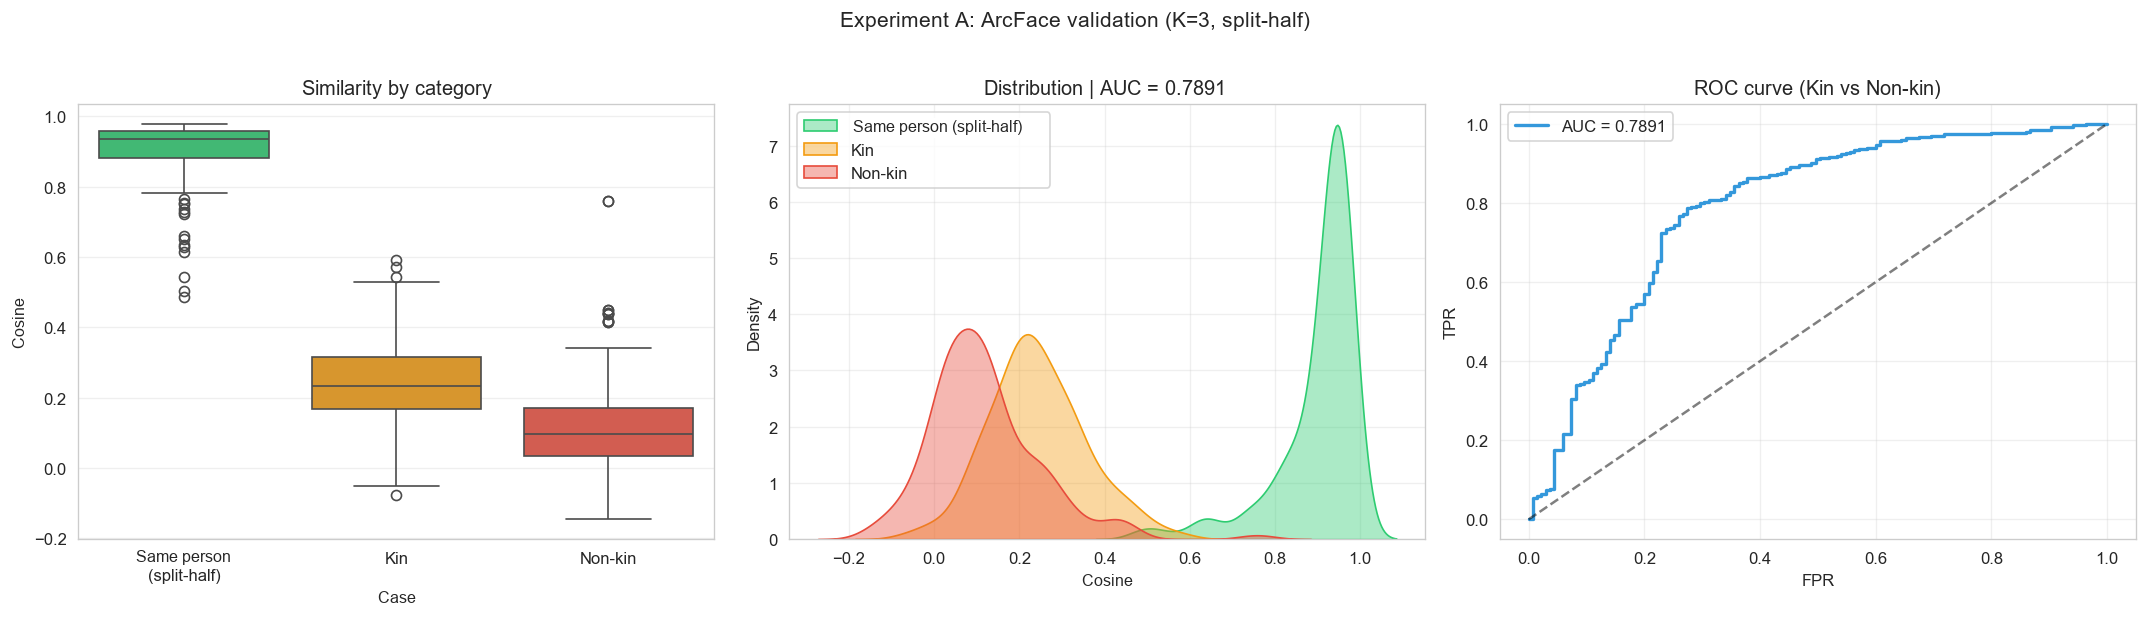

In [ ]:
# ============================================================
# EXPERIMENTO A: KIN vs NON-KIN (embeddings promediados)
# ============================================================

N_A = 300
scores_kin, scores_non, scores_misma = [], [], []

print("  Processing...")
intentos = 0

while len(scores_kin) < N_A and intentos < N_A * 5:
    intentos += 1
    row = df.sample(1).iloc[0]
    fam = row['familia']
    if fam not in familias_disco: continue

    mid_h = mid_desde_ruta(row['p2'])
    mid_p = mid_desde_ruta(row['p1_papa'])
    mid_m = mid_desde_ruta(row['p1_mama'])
    if not mid_h or not mid_p or not mid_m: continue

    # Embeddings promediados (K=3)
    v_h = embedding_promedio(fam, mid_h, 3)
    v_p = embedding_promedio(fam, mid_p, 3)
    v_m = embedding_promedio(fam, mid_m, 3)
    if v_h is None or v_p is None or v_m is None: continue

    # Kin: father-child and mother-child separately
    scores_kin.append(coseno(v_p, v_h))
    scores_kin.append(coseno(v_m, v_h))

    # Same person: split-half (half vs half of the photos)
    fotos_h = listar_fotos(RUTA_FIDS / fam / mid_h)
    if len(fotos_h) >= 4:
        random.shuffle(fotos_h)
        mitad = len(fotos_h) // 2
        half_a = fotos_h[:mitad]
        half_b = fotos_h[mitad:]

        embs_a = [obtener_embedding(fam, mid_h, f) for f in half_a]
        embs_b = [obtener_embedding(fam, mid_h, f) for f in half_b]
        embs_a = [e for e in embs_a if e is not None]
        embs_b = [e for e in embs_b if e is not None]

        if embs_a and embs_b:
            avg_a = np.mean(embs_a, axis=0).astype(np.float32)
            avg_a = avg_a / (np.linalg.norm(avg_a) + 1e-8)
            avg_b = np.mean(embs_b, axis=0).astype(np.float32)
            avg_b = avg_b / (np.linalg.norm(avg_b) + 1e-8)
            scores_misma.append(coseno(avg_a, avg_b))

    # Non-kin: child vs a person from another family
    fam_ex = random.choice(list(familias_disco - {fam}))
    mids_ex = [m for m in os.listdir(RUTA_FIDS / fam_ex)
               if os.path.isdir(RUTA_FIDS / fam_ex / m)]
    if not mids_ex: continue
    mid_ex = random.choice(mids_ex)
    v_ex = embedding_promedio(fam_ex, mid_ex, 3)
    if v_ex is None: continue
    scores_non.append(coseno(v_h, v_ex))
    scores_non.append(coseno(v_h, v_ex))

    if len(scores_kin) % 100 == 0:
        print(f"    {len(scores_kin)} pares...")

# ── Metrics ──────────────────────────────────────────────────

y_true   = [1] * len(scores_kin) + [0] * len(scores_non)
y_scores = scores_kin + scores_non
auc      = roc_auc_score(y_true, y_scores)
stat, pval = mannwhitneyu(scores_kin, scores_non, alternative='greater')

print(f"\n{'='*60}")
print(f"{'EXPERIMENTO A: KIN vs NON-KIN':^60}")
print(f"{'='*60}")
print(f"  {'Misma persona (split-half):':<30} n={len(scores_misma):<6} media={np.mean(scores_misma):.4f} ± {np.std(scores_misma):.4f}")
print(f"  {'Kin:':<30} n={len(scores_kin):<6} media={np.mean(scores_kin):.4f} ± {np.std(scores_kin):.4f}")
print(f"  {'Non-kin:':<30} n={len(scores_non):<6} media={np.mean(scores_non):.4f} ± {np.std(scores_non):.4f}")
print(f"  {'─'*50}")
print(f"  {'AUC:':<30} {auc:.4f}")
print(f"  {'Mann-Whitney p-value:':<30} {pval:.4e}")
print(f"{'='*60}")

# ── Plots ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Boxplot
data_box = pd.DataFrame([
    *[{'Case': 'Same person\n(split-half)', 'Cosine': s} for s in scores_misma],
    *[{'Case': 'Kin', 'Cosine': s} for s in scores_kin],
    *[{'Case': 'Non-kin', 'Cosine': s} for s in scores_non],
])
orden = ['Same person\n(split-half)', 'Kin', 'Non-kin']
colores = ['#2ecc71', '#f39c12', '#e74c3c']
sns.boxplot(data=data_box, x='Case', y='Cosine', order=orden,
            palette=colores, ax=axes[0])
axes[0].set_title('Similarity by category')
axes[0].grid(axis='y', alpha=0.3)

# KDE
for caso, col in zip(orden, colores):
    sub = data_box[data_box['Case'] == caso]['Cosine']
    if len(sub) > 1:
        sns.kdeplot(sub, fill=True, label=caso.replace('\n', ' '),
                    color=col, alpha=0.4, ax=axes[1])
axes[1].set_title(f'Distribution | AUC = {auc:.4f}')
axes[1].legend()
axes[1].grid(alpha=0.3)

# ROC
fpr, tpr, _ = roc_curve(y_true, y_scores)
axes[2].plot(fpr, tpr, color='#3498db', lw=2, label=f'AUC = {auc:.4f}')
axes[2].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[2].set_title('ROC curve (Kin vs Non-kin)')
axes[2].set_xlabel('FPR')
axes[2].set_ylabel('TPR')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle('Experiment A: ArcFace validation (K=3, split-half)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Experiment B: Similarity by relationship type

  Processing triads...
    50/200 triads...
    100/200 triads...
    150/200 triads...
    200/200 triads...

            EXPERIMENT B: BY RELATIONSHIP TYPE             
     Relationship   N   Mean    Std     Min    Max
 Father → Son 144 0.2833 0.1184 -0.0417 0.5760
 Father → Daughter  56 0.2324 0.1212 -0.0223 0.6506
 Mother → Daughter  56 0.2157 0.1388 -0.0336 0.5205
 Mother → Son 144 0.2030 0.1096 -0.0376 0.4648
Father ↔ Mother 200 0.1334 0.1141 -0.1694 0.4540
Non-kin 200 0.1131 0.1185 -0.1809 0.7788


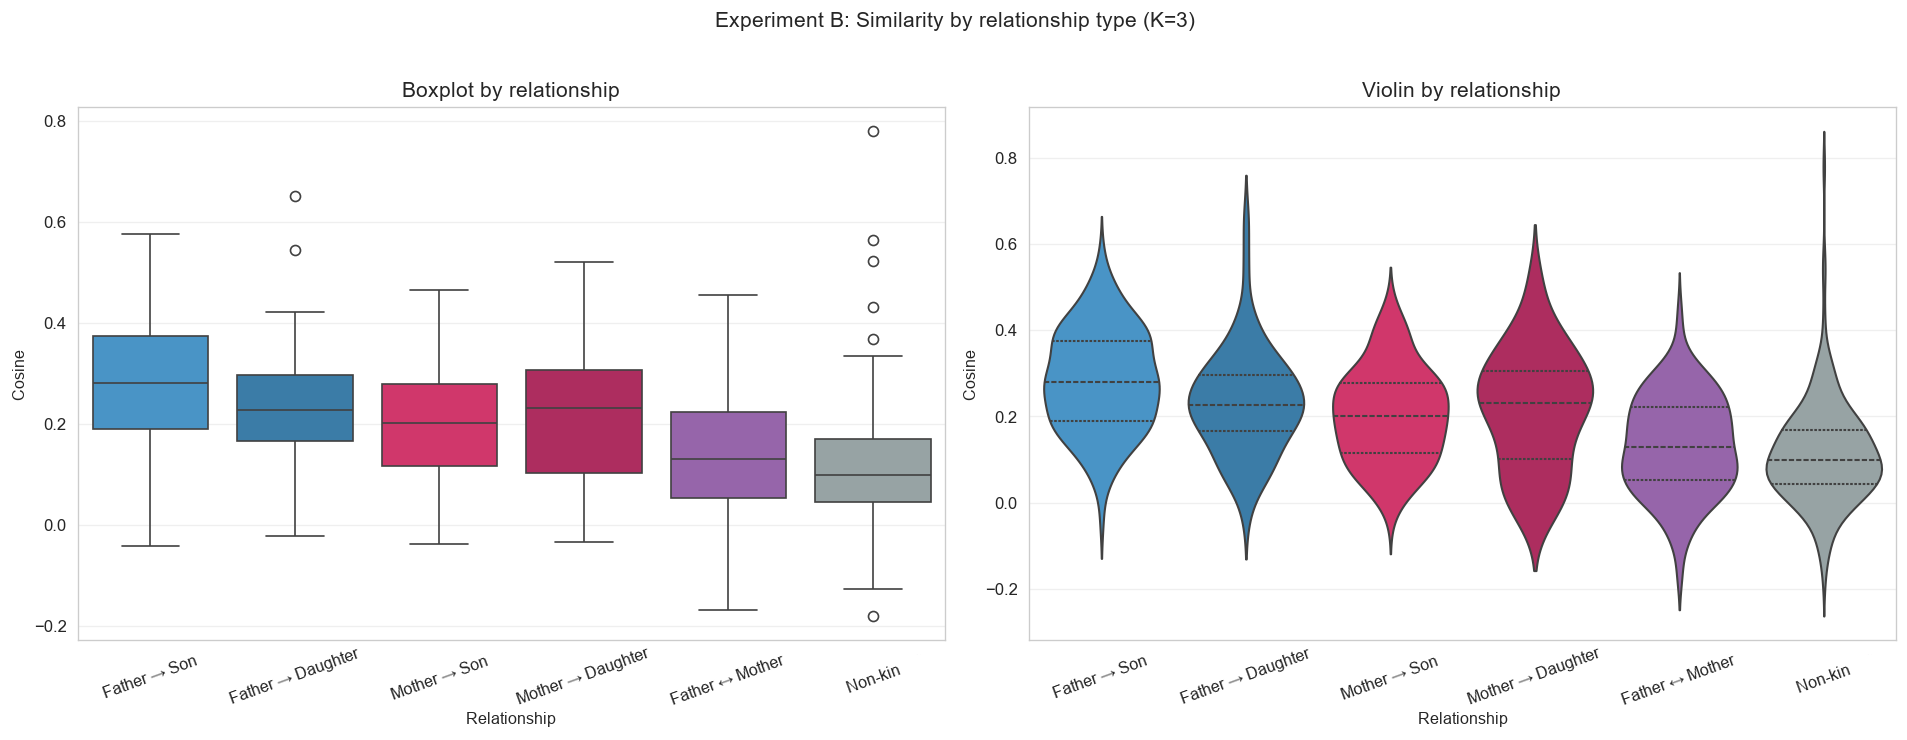

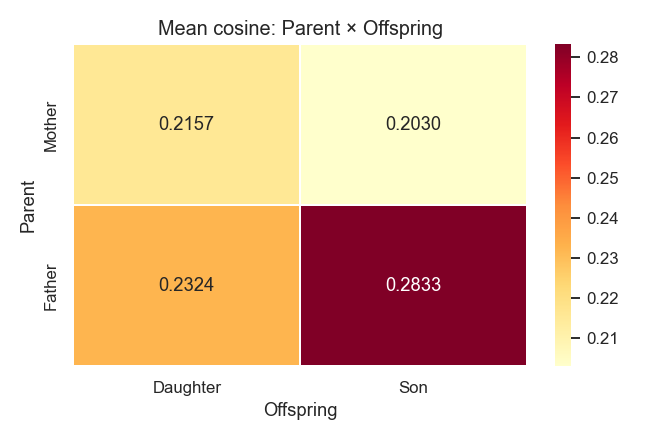

In [ ]:
# ============================================================
# EXPERIMENT B: SIMILARITY BY RELATIONSHIP TYPE
# Do children look more like the father or the mother?
# Father→Son vs Father→Daughter?
# ============================================================

N_B = 200
relaciones = []
intentos = 0

print("  Processing triads...")

while len(relaciones) // 4 < N_B and intentos < N_B * 10:
    intentos += 1
    row = df.sample(1).iloc[0]
    fam = row['familia']
    if fam not in familias_disco: continue

    mid_p = mid_desde_ruta(row['p1_papa'])
    mid_m = mid_desde_ruta(row['p1_mama'])
    mid_h = mid_desde_ruta(row['p2'])
    if not mid_p or not mid_m or not mid_h: continue

    genero = obtener_genero(fam, mid_h)
    if not genero: continue

    # Embeddings promediados K=3
    v_p = embedding_promedio(fam, mid_p, 3)
    v_m = embedding_promedio(fam, mid_m, 3)
    v_h = embedding_promedio(fam, mid_h, 3)
    if v_p is None or v_m is None or v_h is None: continue

    # Non-kin control
    fam_ex = random.choice(list(familias_disco - {fam}))
    mids_ex = [m for m in os.listdir(RUTA_FIDS / fam_ex)
               if os.path.isdir(RUTA_FIDS / fam_ex / m)]
    if not mids_ex: continue
    mid_ex = random.choice(mids_ex)
    v_ex = embedding_promedio(fam_ex, mid_ex, 3)
    if v_ex is None: continue

    relaciones.append({'Relationship': f'Father → {genero}',  'Cosine': coseno(v_p, v_h)})
    relaciones.append({'Relationship': f'Mother → {genero}',  'Cosine': coseno(v_m, v_h)})
    relaciones.append({'Relationship': 'Father ↔ Mother',      'Cosine': coseno(v_p, v_m)})
    relaciones.append({'Relationship': 'Non-kin',       'Cosine': coseno(v_h, v_ex)})

    n = len(relaciones) // 4
    if n % 50 == 0:
        print(f"    {n}/{N_B} triads...")

# ── Results ───────────────────────────────────────────────────

df_b = pd.DataFrame(relaciones)
resumen_b = df_b.groupby('Relationship')['Cosine'].agg(
    ['count', 'mean', 'std', 'min', 'max']
).round(4).reset_index()
resumen_b.columns = ['Relationship', 'N', 'Mean', 'Std', 'Min', 'Max']
resumen_b = resumen_b.sort_values('Media', ascending=False)

print(f"\n{'='*60}")
print(f"{'EXPERIMENT B: BY RELATIONSHIP TYPE':^60}")
print(f"{'='*60}")
imprimir_tabla(resumen_b)

# ── Plots ─────────────────────────────────────────────────────

orden_b = ['Father → Son', 'Father → Daughter', 'Mother → Son', 'Mother → Daughter',
           'Father ↔ Mother', 'Non-kin']
colores_b = ['#3498db', '#2980b9', '#e91e63', '#c2185b', '#9b59b6', '#95a5a6']

# Keep only existing categories
existentes = df_b['Relationship'].unique()
orden_b  = [o for o in orden_b if o in existentes]
colores_b = colores_b[:len(orden_b)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df_b, x='Relationship', y='Cosine', order=orden_b,
            palette=colores_b, ax=axes[0])
axes[0].set_title('Boxplot by relationship')
axes[0].tick_params(axis='x', rotation=20)
axes[0].grid(axis='y', alpha=0.3)

sns.violinplot(data=df_b, x='Relationship', y='Cosine', order=orden_b,
               palette=colores_b, inner='quartile', ax=axes[1])
axes[1].set_title('Violin by relationship')
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle('Experiment B: Similarity by relationship type (K=3)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# ── Heatmap progenitor × descendiente ────────────────────────

pivot = df_b[df_b['Relationship'].str.contains('→')].copy()
pivot['Parent']   = pivot['Relationship'].apply(lambda x: x.split(' →')[0])
pivot['Offspring'] = pivot['Relationship'].apply(lambda x: x.split('→ ')[1])
tabla_heat = pivot.groupby(['Parent', 'Offspring'])['Cosine'].mean().unstack()

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(tabla_heat, annot=True, fmt='.4f', cmap='YlOrRd',
            linewidths=1, ax=ax)
ax.set_title('Media coseno: Progenitor × Descendiente')
plt.tight_layout()
plt.show()